# Notizbuch zum Analysieren und verstehen des MNIST HAM10000 Datensatz

**Autoren**
- [1] Noel Codella, Veronica Rotemberg, Philipp Tschandl, M. Emre Celebi, Stephen Dusza, David Gutman, Brian Helba, Aadi Kalloo, Konstantinos Liopyris, Michael Marchetti, Harald Kittler, Allan Halpern: "Skin Lesion Analysis Toward Melanoma Detection 2018: A Challenge Hosted by the International Skin Imaging Collaboration (ISIC)", 2018; https://arxiv.org/abs/1902.03368
- [2] Tschandl, P., Rosendahl, C. & Kittler, H. The HAM10000 dataset, a large collection of multi-source dermatoscopic images of common pigmented skin lesions. Sci. Data 5, 180161 doi:10.1038/sdata.2018.161 (2018).

**Generelle Eckdaten**
- verwendet für den ISIC 2018 Wettkampf 
    - Subziele: Umriss der Hautläsion erkennen, Läsionen-Mekmale feststellen (z.B. gepunktet, Streifen etc.), Labeln von Hautläsionen
- eine Metadaten Datei (`HAM10000_metadata.csv`) mit Spalten `lesion_id`, `image_id`, `dx` (Diagnose), `dx_type` (Diagnose-Methode), `age` (Alter), `sex` (Geschlecht), `localization` (Körperteil)
- zwei Ordner mit Bilder (600x450) entsprechend image_id
- 4 .csv Dateien mit komprimierten Pixelrohwerten (sowohl '8x8' als auch '28x28') und `dx`-Label für RGB und HLS (?)

**Diagnose-Typen (`dx`)**
- `nv`: Melanocytic nevi (Melanozytärer Nävus / gewöhnliches Muttermal)
- `mel`: Melanoma (Melanom / schwarzer Hautkrebs)
- `bkl`: Benign keratosis-like lesions (Gutartige Keratose-ähnliche Läsionen)
- `bcc`: Basal cell carcinoma (Basalzellkarzinom)
- `akiec`: Actinic keratoses / Intraepithelial carcinoma (Aktinische Keratose / intraepitheliales Karzinom)
- `vasc`: Vascular lesions (Vaskuläre Läsionen)
- `df`: Dermatofibroma (Dermatofibrom)

**Diagnose-Methoden (`dx_type`)**
- `histo`: Histopathologisch bestätigt (durch Gewebeuntersuchung)
- `follow_up`: Durch Verlaufskontrolle bestätigt
- `consensus`: Durch Expertenkonsens bestätigt
- `confocal`: Durch konfokale Mikroskopie bestätigt

## Imports und dataframe aufbauen

In [2]:
import kagglehub
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt
import seaborn as sns

# kagglehub.login()

In [3]:
dataset_path = kagglehub.dataset_download("kmader/skin-cancer-mnist-ham10000")
print("Path to dataset files:", dataset_path)

metadata_file = os.path.join(dataset_path, "HAM10000_metadata.csv")
df = pd.read_csv(metadata_file)

100%|██████████| 5.20G/5.20G [04:32<00:00, 20.5MB/s]

Extracting files...


Path to dataset files: /home/z004ps0b/.cache/kagglehub/datasets/kmader/skin-cancer-mnist-ham10000/versions/2


**Datensatz um vollständigen medizinischen Namen erweitern**

In [4]:
from glob import glob

lesion_type_dict = {
    'nv': 'Melanocytic nevi',
    'mel': 'Melanoma',
    'bkl': 'Benign keratosis-like lesions ',
    'bcc': 'Basal cell carcinoma',
    'akiec': 'Actinic keratoses',
    'vasc': 'Vascular lesions',
    'df': 'Dermatofibroma'
}


imageid_path_dict = {os.path.splitext(os.path.basename(x))[0]: x
                     for x in glob(os.path.join(dataset_path, '*', '*.jpg'))}


df['path'] = df['image_id'].map(imageid_path_dict.get)
df['cell_type'] = df['dx'].map(lesion_type_dict.get) 
df['cell_type_idx'] = pd.Categorical(df['cell_type']).codes
df.head()



,lesion_id,image_id,dx,dx_type,age,sex,localization,path,cell_type,cell_type_idx
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp,/home/z004ps0b/.cache/kagglehub/datasets/kmade...,Benign keratosis-like lesions,2
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp,/home/z004ps0b/.cache/kagglehub/datasets/kmade...,Benign keratosis-like lesions,2
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp,/home/z004ps0b/.cache/kagglehub/datasets/kmade...,Benign keratosis-like lesions,2
3,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp,/home/z004ps0b/.cache/kagglehub/datasets/kmade...,Benign keratosis-like lesions,2
4,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear,/home/z004ps0b/.cache/kagglehub/datasets/kmade...,Benign keratosis-like lesions,2


**Leere Daten filtern** 

In [5]:
print("Before:\n", df.isnull().sum())
df.fillna({'age': (df['age'].mean())}, inplace=True)
print("\nAfter:\n", df.isnull().sum())

features=df.drop(columns=['cell_type_idx'],axis=1)
target=df['cell_type_idx']

# features.to_csv('../data/features.csv', index=False)
# target.to_csv('../data/target.csv', index=False)

Before:
 lesion_id         0
image_id          0
dx                0
dx_type           0
age              57
sex               0
localization      0
path              0
cell_type         0
cell_type_idx     0
dtype: int64

After:
 lesion_id        0
image_id         0
dx               0
dx_type          0
age              0
sex              0
localization     0
path             0
cell_type        0
cell_type_idx    0
dtype: int64


In [6]:
plt.style.use('dark_background')
plt.rcParams['figure.figsize'] = [12, 6]

## Visualisierung der Datensatzmerkmale

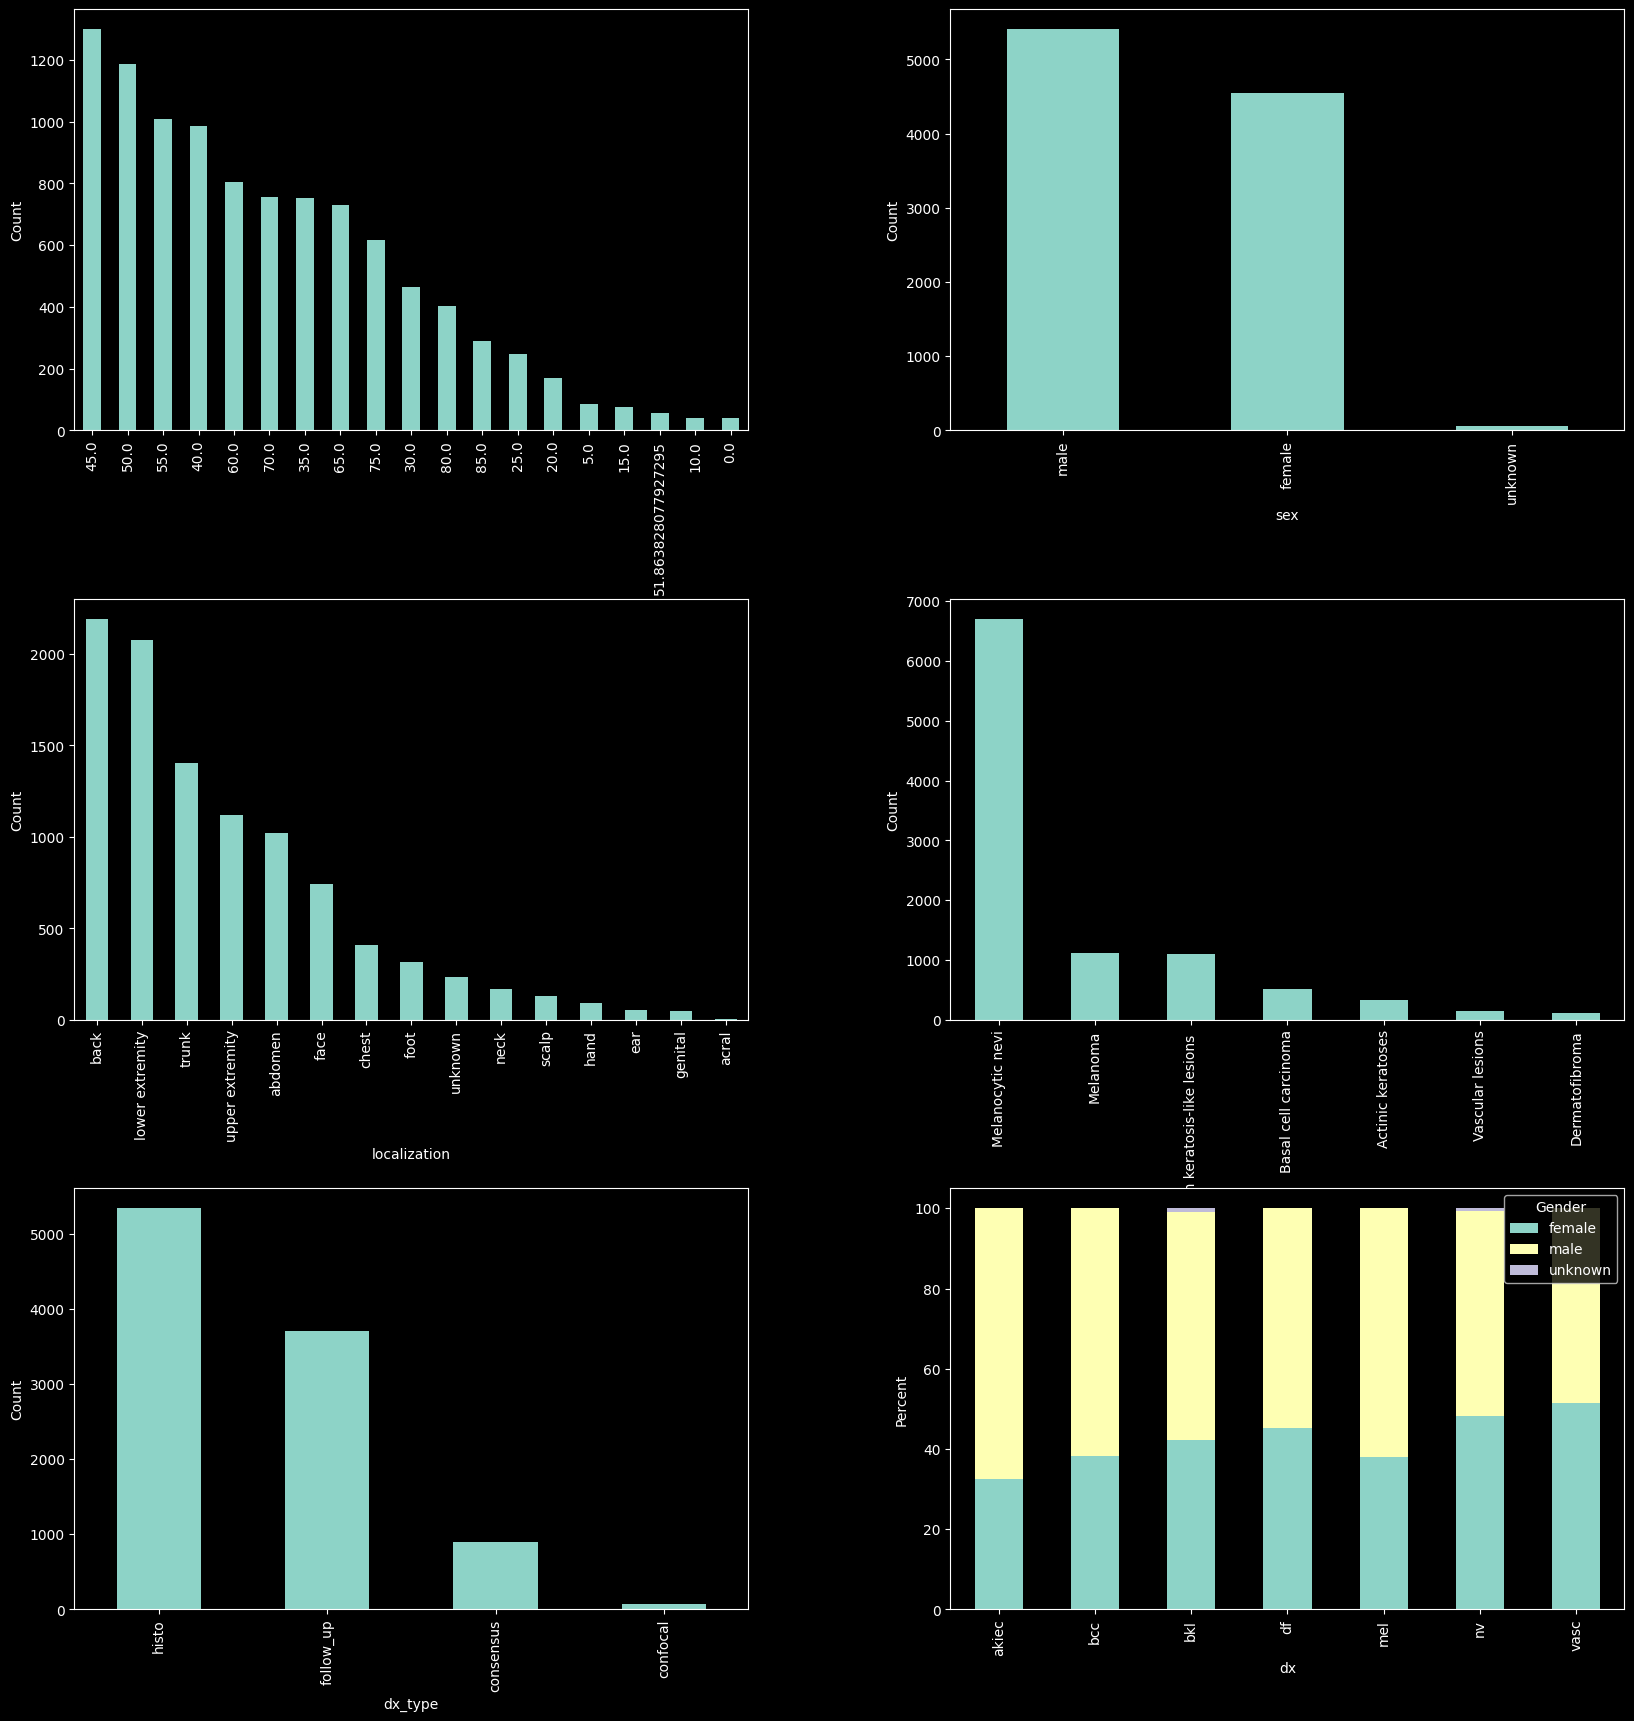

In [7]:
plt.figure(figsize=(20,20))
plt.subplots_adjust(left=0.125, bottom=0.1, right=0.9, top=0.9, hspace=0.4, wspace=0.3)

plt.subplot(3,2,1)
plt.ylabel("Count")
df['age'].value_counts().plot.bar()

plt.subplot(3,2,2)
plt.ylabel("Count")
df['sex'].value_counts().plot.bar()

plt.subplot(3,2,3)
plt.ylabel("Count")
plt.xticks(rotation=45)
df['localization'].value_counts().plot.bar()

plt.subplot(3,2,4)
plt.ylabel("Count")
df['cell_type'].value_counts().plot.bar()

plt.subplot(3,2,5)
plt.ylabel("Count")
df['dx_type'].value_counts().plot.bar()

plt.subplot(3,2,6)
plt.ylabel("Percent")
gender_diag = pd.crosstab(df['dx'], df['sex'], normalize='index') * 100
gender_diag.plot(kind='bar', stacked=True, ax=plt.gca())
plt.legend(title='Gender')

plt.show()